# Dynesty results — visualization

`run_dynesty1.py` writes one pickle per insolation model; `load_fits` reads them back as the `{model: NestedFit}` dict every plotting helper takes. Each fit carries **its own data, priors, injected truth and `FittingConfig`**, so nothing has to be re-typed here — `logl_from_fit` rebuilds the exact likelihood the sampler used (needed by 1.–2. and by the posterior predictive, which still evaluate the forward model).

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from dynesty_utils import *
from dynesty import utils as dyfunc, plotting as dyplot
from dataclasses import replace
import glob, os

N_JOBS = -1      # forward models run process-parallel (loky); the plots below are the only likelihood cost
COLOR  = {"naive": "C0", "hyperillum": "C3"}

In [ ]:
# --- load data file ---------------------------------------------------------------------------------------
# one pattern matching BOTH models of one run
results_file = [# K2-141 b
                "K2-141b_JWST_NIRSpec.G395H_NRS1_fixedA0.1_AB0.42_priors-A_B+offset_nbins27_sigmascale1_seed42",
                "K2-141b_MIRI-LRS_fixedA0.1_AB0.1_priors-A_B+offset_nbins27_sigmascale1_seed42",
                "K2-141b_MIRI-LRS_fixedA0.1_AB0.42_priors-A_B+offset_nbins27_sigmascale0.1_seed42",
                "K2-141b_MIRI-LRS_fixedA0.1_AB0.42_priors-A_B+offset_nbins27_sigmascale0.5_seed42",
                "K2-141b_MIRI-LRS_fixedA0.1_AB0.42_priors-A_B+offset_nbins27_sigmascale1_seed42",
                "K2-141b_MIRI-LRS_scaledA1_AB0.42_priors-A_B+offset_nbins27_sigmascale1_seed42",
                # TOI-2431 b
                "TOI-2431b_JWST_NIRSpec.G395H_NRS1_fixedA0.1_AB0.42_priors-A_B+offset_nbins27_sigmascale1_seed42",
                "TOI-2431b_MIRI-F1280W_fixedA0.1_AB0.42_priors-A_B+offset_nbins27_sigmascale1_seed42",
                "TOI-2431b_MIRI-LRS_fixedA0.1_AB0.42_priors-A_B+offset_nbins27_sigmascale0.1_seed42",
                "TOI-2431b_MIRI-LRS_fixedA0.1_AB0.42_priors-A_B+offset_nbins27_sigmascale0.5_seed42",
                "TOI-2431b_MIRI-LRS_fixedA0.1_AB0.42_priors-A_B+offset_nbins27_sigmascale1_seed42",
                # K2-157 b
                "K2-157b_MIRI-LRS_fixedA0.1_AB0.42_priors-A_B+offset_nbins27_sigmascale1_seed42",
                # KOI-1843.03
                "KOI-1843.03_MIRI-LRS_fixedA0.1_AB0.42_priors-A_B+offset_nbins27_sigmascale1_seed42",
                # TOI-2260 b
                "TOI-2260b_MIRI-LRS_fixedA0.1_AB0.42_priors-A_B+offset_nbins27_sigmascale1_seed42",
                ]
RESULTS = f"dynesty_results/{results_file[0]}_*.pkl"

In [2]:
fits  = load_fits(RESULTS)                                    # {insolation_model: NestedFit}
logls = {m: logl_from_fit(f) for m, f in fits.items()}        # the likelihood each fit was run with, rebuilt from its own cfg

f0    = next(iter(fits.values()))
pset  = f0.pset
cfg   = f0.meta["cfg"]
data  = f0.meta["data"]
truth = data["truth"]                                          # what simulate_data injected
A_B_true, INSOL_TRUTH = truth["A_B"], truth["insolation_model"]
base  = dict(A_B=A_B_true, offset=truth["offset"])              # the injected truth, in pset order

print(f"{cfg.planet.name}   truth = {INSOL_TRUTH}, A_B = {A_B_true:g}, offset = {truth['offset']:g} ppm, data seed = {truth['seed']}")
print(f"{cfg.n_bins} bins over {cfg.n_orbits} orbits, sigma_bin = {cfg.sigma_bin:.1f} ppm   |   free: {pset.names}\n")
print(f"{'model':12s} {'lnZ':>20s} {'ncall':>8s} {'runtime':>9s}   status   (ESS is part of the status line)")
for m, f in fits.items():
    print(f"{m:12s} {f.meta['lnZ']:10.4f} +/- {f.meta['lnZ_err']:.4f} {f.meta['ncall']:8d} {f.meta['runtime_s']/60:7.1f} m   {f.meta['status']}")
    print(f"{'':12s} {os.path.basename(f.meta.get('file', '(not saved)'))}")

K2-141 b   truth = hyperillum, A_B = 0.42, offset = 0 ppm, data seed = 42
27 bins over 3 orbits, sigma_bin = 23.1 ppm   |   free: ('A_B', 'offset')

model                         lnZ    ncall   runtime   status   (ESS is part of the status line)
hyperillum    -120.8287 +/- 0.0388    40140    14.6 m   CONVERGED | stop 0.963, 9/10 batches, ESS 9039
             K2-141b_MIRI-LRS_fixedA0.1_AB0.42_priors-A_B+offset_nbins27_sigmascale1_seed42_hyperillum.pkl
naive         -120.1418 +/- 0.0384    42634    21.4 m   CONVERGED | stop 0.982, 9/10 batches, ESS 8837
             K2-141b_MIRI-LRS_fixedA0.1_AB0.42_priors-A_B+offset_nbins27_sigmascale1_seed42_naive.pkl


## 1. Likelihood

Plotted as $\Delta\ln\mathcal{L}=\ln\mathcal{L}-\ln\mathcal{L}_{\max}$. In the slices the dotted lines at $-0.5,-2,-4.5$ are the 1-parameter $1/2/3\sigma$ levels; in the map the contours are the 2-parameter ones ($-1.15,-3.09,-5.91$). With uniform priors $\exp(\ln\mathcal{L})$ over this box *is* the un-normalised posterior, so the map previews the corner plot in 2.

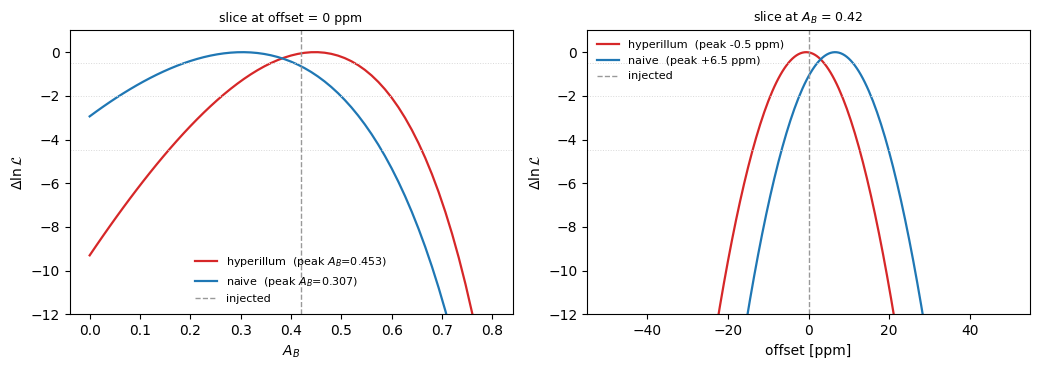

hyperillum  grid MAP: A_B = 0.4667, offset = +1.50 ppm, lnL = -117.812
naive       grid MAP: A_B = 0.4133, offset = +6.50 ppm, lnL = -117.227


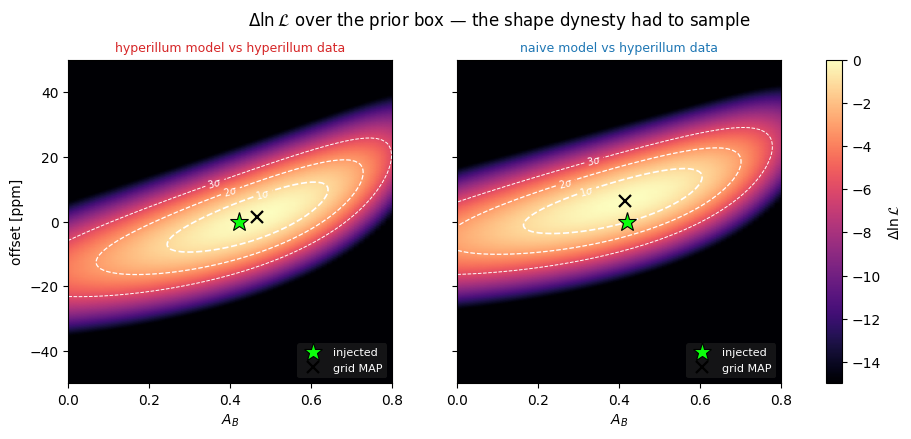

In [3]:
A_grid, O_grid = pset.grid("A_B", 61),  pset.grid("offset", 201)

# 1D slices
fig, (axA, axO) = plt.subplots(1, 2, figsize=(10.5, 3.8))
for name, L in logls.items():
    sA = logl_slice(L, "A_B",    A_grid, base, n_jobs=N_JOBS)   # 61 forward models per insolation model
    sO = logl_slice(L, "offset", O_grid, base, n_jobs=N_JOBS)   # free: the offset is additive
    axA.plot(A_grid, sA - sA.max(), color=COLOR[name], lw=1.6, label=f"{name}  (peak $A_B$={A_grid[sA.argmax()]:.3f})")
    axO.plot(O_grid, sO - sO.max(), color=COLOR[name], lw=1.6, label=f"{name}  (peak {O_grid[sO.argmax()]:+.1f} ppm)")

for ax, tr, xl in ((axA, A_B_true, "$A_B$"), (axO, base["offset"], "offset [ppm]")):
    for d in (-0.5, -2.0, -4.5):
        ax.axhline(d, color="0.85", lw=0.7, ls=":")
    ax.axvline(tr, color="0.6", lw=1.0, ls="--", label="injected")
    ax.set_xlabel(xl); ax.set_ylabel(r"$\Delta\ln\mathcal{L}$")
    ax.set_ylim(-12, 1.); ax.legend(frameon=False, fontsize=8)
axA.set_title(f"slice at offset = {base['offset']:g} ppm", fontsize=9)
axO.set_title(f"slice at $A_B$ = {base['A_B']:g}", fontsize=9)
plt.tight_layout(); plt.show()

# 2D map
lnL_maps = {}
for name, L in logls.items():
    lnL = logl_grid(L, "A_B", A_grid, "offset", O_grid, base, n_jobs=N_JOBS)   # (n_off, n_A_B)
    lnLmax, (off_map, A_map) = grid_max(lnL, O_grid, A_grid)                   # axis order of lnL: (offset, A_B)
    lnL_maps[name] = (lnL, lnLmax, A_map, off_map)
    print(f"{name:11s} grid MAP: A_B = {A_map:.4f}, offset = {off_map:+.2f} ppm, lnL = {lnLmax:.3f}")

fig, axes = plt.subplots(1, 2, figsize=(11.5, 4.2), sharex=True, sharey=True)
for ax, (name, (lnL, lnLmax, A_map, off_map)) in zip(axes, lnL_maps.items()):
    d = lnL - lnLmax
    im = ax.pcolormesh(A_grid, O_grid, d, vmin=-15, vmax=0., cmap="magma", shading="gouraud")
    cs = ax.contour(A_grid, O_grid, d, levels=[-5.91, -3.09, -1.15], colors="w", linewidths=[0.7, 0.9, 1.2])
    ax.clabel(cs, fmt={-5.91: r"3$\sigma$", -3.09: r"2$\sigma$", -1.15: r"1$\sigma$"}, fontsize=7)
    ax.plot(A_B_true, base["offset"], "*", ms=14, mfc="#0cff0c", mec="k", mew=.8, label="injected")   # not C0/C3: those now mean naive/hyperillum
    ax.plot(A_map, off_map, "x", ms=9, color="k", mew=1.6, label="grid MAP")   # the MAP always sits in the bright peak
    ax.set_xlabel("$A_B$")
    ax.set_title(f"{name} model vs {INSOL_TRUTH} data", fontsize=9, color=COLOR[name])
    ax.legend(loc="lower right", fontsize=8, labelcolor="w", facecolor="0.15", edgecolor="none", framealpha=.55)
axes[0].set_ylabel("offset [ppm]")
fig.colorbar(im, ax=axes, label=r"$\Delta\ln\mathcal{L}$")   # shared: both panels use vmin=-15, vmax=0
fig.suptitle(r"$\Delta\ln\mathcal{L}$ over the prior box — the shape dynesty had to sample", y=1.0)
plt.show()

## 2. Dynesty results

Posterior overlay (filled: the sampler's 68/95% credible regions from `samples_equal()`; dotted: the profile-likelihood contours from 1.), the per-parameter bias against the injected truth, the Bayes factor, and the one-seed fits against the noiseless truth.

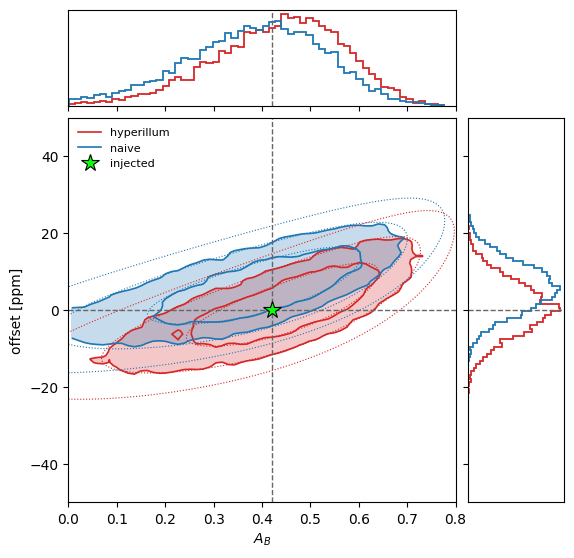

hyperillum   ESS 9039, information 2.03 nats
   A_B      =    0.4455 +0.1189 -0.1467   truth 0.42, bias +0.0255 = +0.19 sigma
   offset   =    0.4063 +6.9684 -6.9323   truth 0, bias +0.4063 = +0.06 sigma
   corr(A_B, offset) = +0.770
naive   ESS 8837, information 1.97 nats
   A_B      =    0.3932 +0.1312 -0.1516   truth 0.42, bias -0.0268 = -0.19 sigma
   offset   =    5.6990 +6.4260 -6.3556   truth 0, bias +5.6990 = +0.89 sigma
   corr(A_B, offset) = +0.722
ln B (hyperillum vs naive) = -0.687 +/- 0.055 (analytic) +/- 0.077 (jitter, K=200)  ->  B = 0.503
P(sign of ln B secure) = 0.000  [sampler noise only, NOT a model probability]


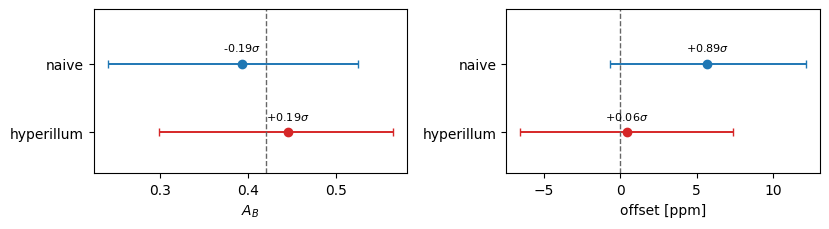

hyperillum  median   A_B 0.4455 (+0.0255 = +0.19 sigma)   offset   +0.41 ppm (+0.41 = +0.06 sigma)   chi2 vs truth   0.10   vs data  16.55
            max-lnL  A_B 0.4681 (+0.0481)              offset   +1.45 ppm (+1.45)           chi2 vs truth   0.18   vs data  16.52
naive       median   A_B 0.3932 (-0.0268 = -0.19 sigma)   offset   +5.70 ppm (+5.70 = +0.89 sigma)   chi2 vs truth   0.66   vs data  15.36
            max-lnL  A_B 0.4138 (-0.0062)              offset   +6.37 ppm (+6.37)           chi2 vs truth   0.71   vs data  15.35

NOISELESS naive vs the NOISELESS truth  (offset free, no noise, no seed - this is THE bias):
   A_B      0.3766   bias -0.0434 = -0.31 sigma_post   ->   dT/T = +1.82 %
   offset absorbed +5.75 ppm    chi2 0.582  (squared truth-to-manifold distance in units of sigma_bin)    resid rms 3.39 ppm = 0.15 sigma_bin
   the noisy naive median instead says -0.0268; the gap to -0.0434 is this one seed's noise (sigma_A_B = 0.1414)

numerical floor: hyperillum at the in

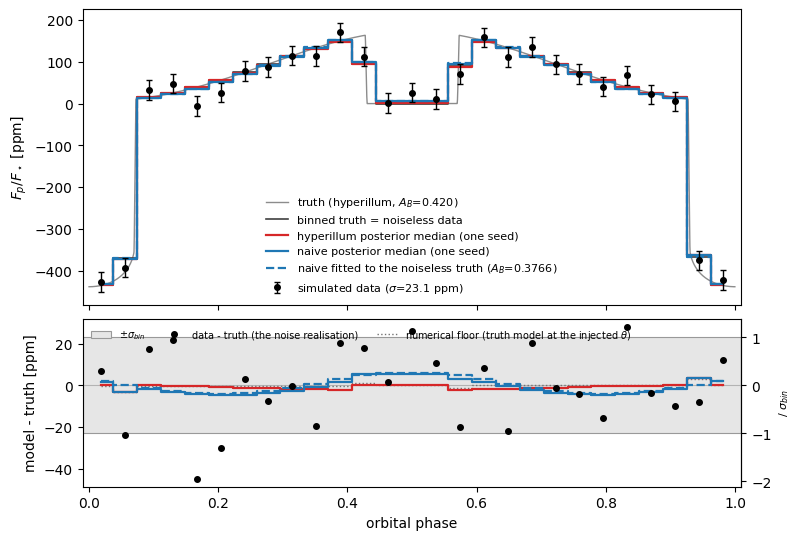

In [4]:
# Posterior
profile = {name: (A_grid, O_grid, lnL) for name, (lnL, *_) in lnL_maps.items()}   # logl_grid returns (offset, A_B), which is what contour(A_grid, O_grid, ...) wants
plot_posterior_overlay(fits, "A_B", "offset", truth=base, profile=profile, colors=COLOR)
plt.show()

# Bayes Factor lnB
for f in fits.values(): posterior_summary(f, base)
bf = bayes_factor(fits, "hyperillum", "naive", K=200)

plot_bias(fits, base, colors=COLOR); plt.show()

# Bias analysis
fig, (ax, axr), out = plot_noisy_vs_truth(cfg, data, logls, fits, A_B_true, base, insolation_truth=INSOL_TRUTH,
                                          A_B_bounds=pset.bounds[pset.names.index("A_B")], colors=COLOR)
plt.show()

## 3. Posterior predictive — and where in phase the evidence comes from

Bottom panel: the difference of the two median curves against $\pm\sigma_{\rm bin}$, plus the per-bin $\Delta\chi^2$ between the two **best-fit** (max-$\ln\mathcal{L}$) models. Those bars sum to $2\,\Delta\ln\mathcal{L}_{\max}$, so they attribute the evidence to specific orbital phases.

Costs `N_DRAWS` forward models per insolation model.

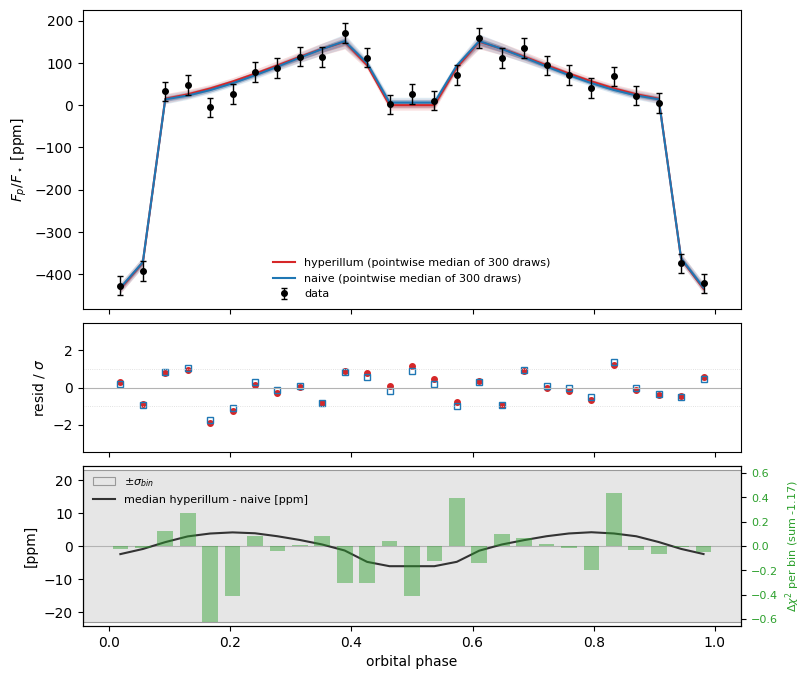

In [5]:
N_DRAWS = 300   # forward models per insolation model

plot_posterior_predictive(logls, fits, n=N_DRAWS, colors=COLOR, n_jobs=N_JOBS)
plt.show() # per-bin Δχ², computed as [(y−best_a)² − (y−best_b)²]/σ², so a bar is positive where model b fits that bin better.

## 4. Derived quantities

The $A_B$ posterior pushed through to physics, each model through **its own** temperature map - i.e. what you would infer if you believed that model.
T_therm(naive)>0 is interpolation artefact.

hyperillum  occultation_depth  168.77 ppm
naive       occultation_depth  167.85 ppm
hyperillum  depth  171.3 +15.9 -13.0 ppm (thermal 166.4, reflected 4.8)   T_bright 2345.6 +148.2 -122.4 K
            T_sub 2637.9 K   T_term 1429.9 K   T_anti   0.0 K
naive       depth  173.7 +16.3 -14.2 ppm (thermal 168.9, reflected 4.8)   T_bright 2369.3 +151.5 -133.5 K
            T_sub 2662.6 K   T_term  537.6 K   T_anti   0.0 K


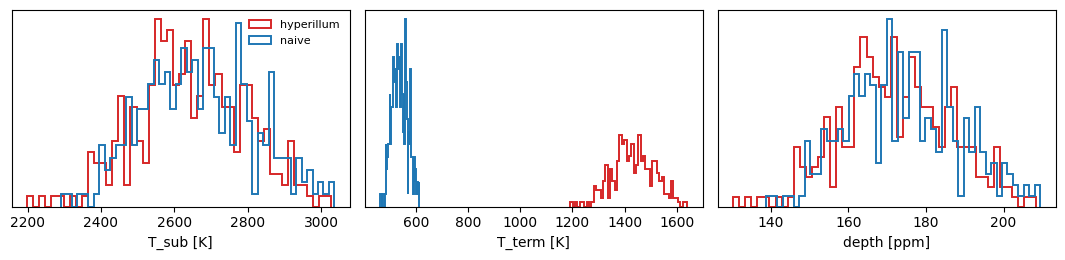

In [6]:
# Check on the factored-out pcurve_params: for a thermal-only, transit-free config the occultation depth must match the peak of the phase curve model_pcurve builds from the same sp.ModelParams.
cfg_th = replace(cfg, reflected=False, transit=False)
for m in fits:
    _, y_ = model_pcurve(cfg_th, m, A_B_true, n_t=200 * cfg.n_bins)
    d_ = occultation_depth(pcurve_params(cfg_th, m, A_B_true), stellar_grid=cfg.stellar_grid)
    print(f"{m:11s} occultation_depth {d_:7.2f} ppm")

der = {m: derived_samples(logls[m], equal_samples(fits[m], N_DRAWS, seed=0), n_jobs=N_JOBS) for m in fits}
for name, d in der.items():
    q, q_th = np.percentile(d["depth"], [16, 50, 84]), np.percentile(d["depth_th"], [16, 50, 84])
    Tb = brightness_temperature(d["depth_th"], cfg)
    print(f"{name:11s} depth {q[1]:6.1f} +{q[2]-q[1]:.1f} -{q[1]-q[0]:.1f} ppm (thermal {q_th[1]:.1f}, reflected {np.median(d['depth_refl']):.1f})   T_bright {Tb[1]:6.1f} +{Tb[2]-Tb[1]:.1f} -{Tb[1]-Tb[0]:.1f} K")
    print(f"{'':11s} T_sub {np.median(d['T_sub']):6.1f} K   T_term {np.median(d['T_term']):6.1f} K   T_anti {np.median(d['T_anti']):5.1f} K")

plot_derived(der, keys=("T_sub", "T_term", "depth"), colors=COLOR); plt.show()